pip install matplotlib numpy scipy

N	Incremental	Jarvis		QuickHull	D&C
-----------------------------------------------------------------
50	0.15ms		0.29ms		0.33ms		0.34ms
200	0.62ms		2.05ms		1.61ms		1.92ms
500	1.76ms		4.12ms		4.28ms		3.9ms
1000	3.33ms		8.28ms		7.67ms		11.94ms


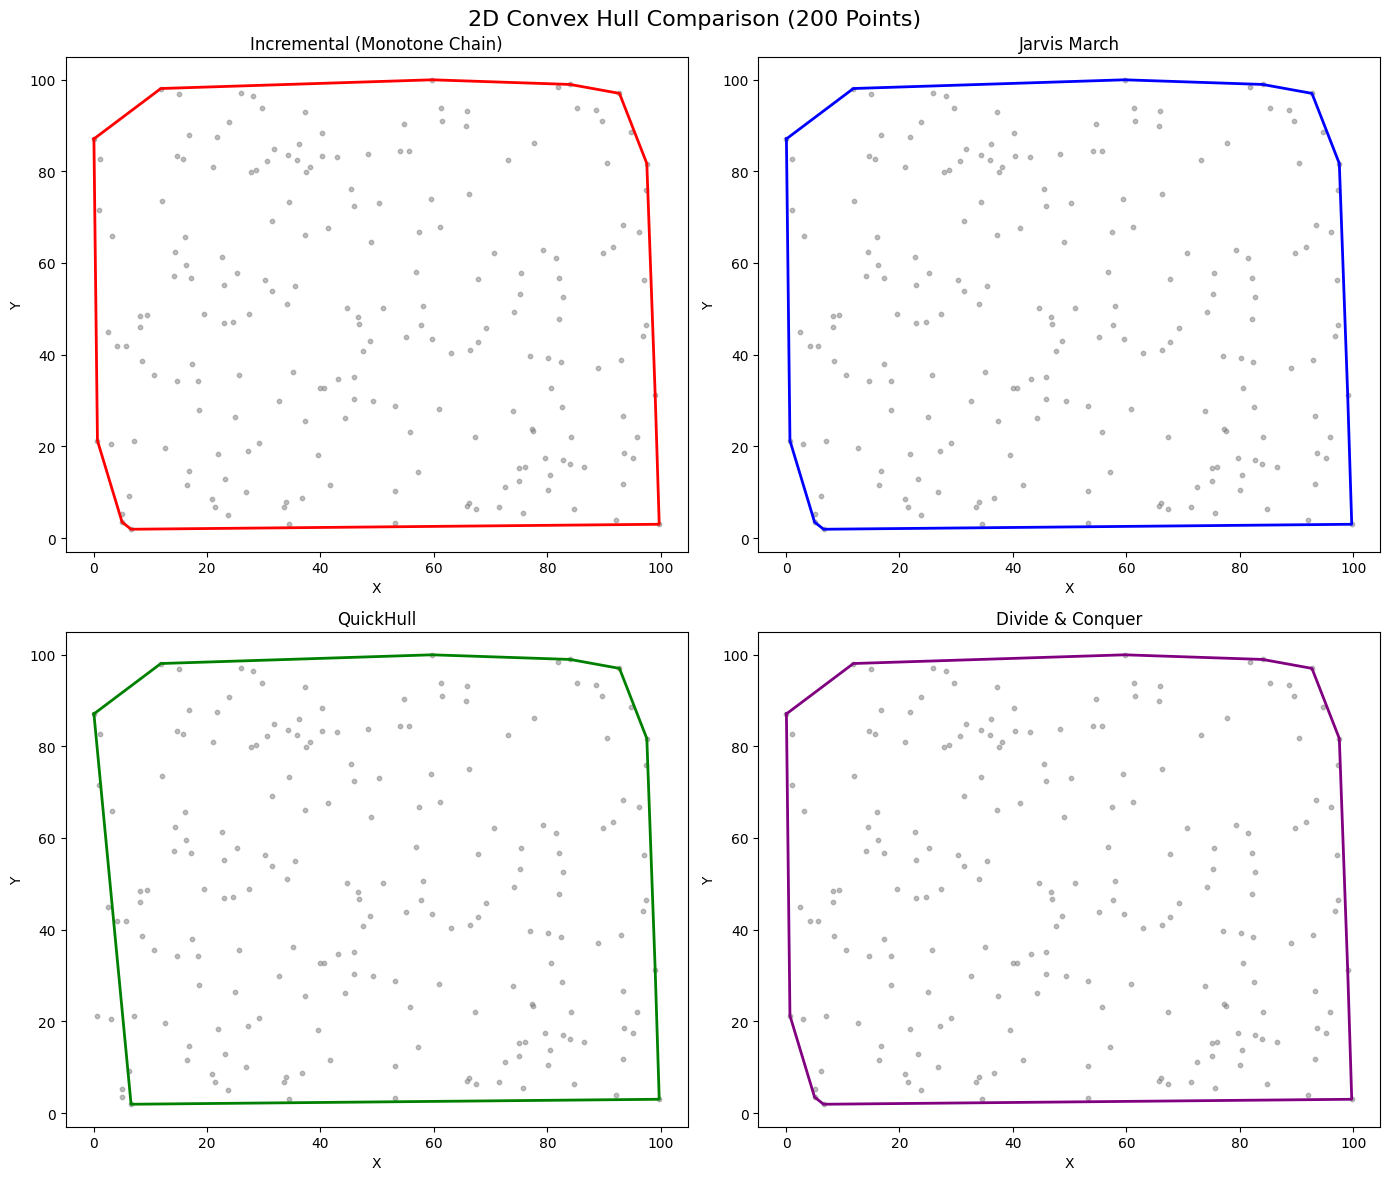

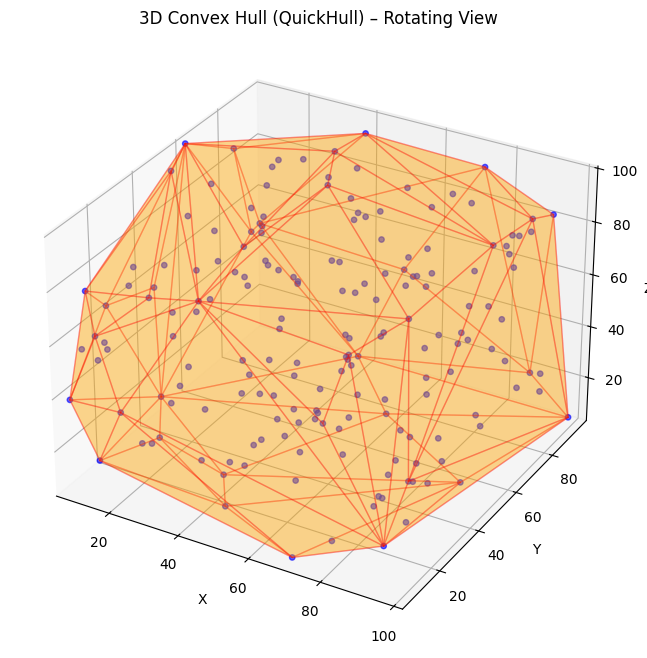

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import time
import sys
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial import ConvexHull as SciPyConvexHull
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib import animation

# Αύξηση του ορίου αναδρομής για να αποφύγουμε το RecursionError
sys.setrecursionlimit(10000)

# --- Βοηθητικές Συναρτήσεις ---
def orientation(p, q, r):
    val = (q[1] - p[1]) * (r[0] - q[0]) - (q[0] - p[0]) * (r[1] - q[1])
    if abs(val) < 1e-9: return 0
    return 1 if val > 0 else 2

# --- 1. Αυξητικός Αλγόριθμος (Monotone Chain) ---
def incremental_hull(points):
    n = len(points)
    if n <= 2: return points
    points.sort()
    upper = []
    for p in points:
        while len(upper) >= 2 and orientation(upper[-2], upper[-1], p) != 2:
            upper.pop()
        upper.append(p)
    lower = []
    for p in reversed(points):
        while len(lower) >= 2 and orientation(lower[-2], lower[-1], p) != 2:
            lower.pop()
        lower.append(p)
    return upper[:-1] + lower[:-1]

# --- 2. Αλγόριθμος Περιτυλίγματος (Jarvis March) ---
def jarvis_march(points):
    n = len(points)
    if n < 3: return points
    hull = []
    l = 0
    for i in range(1, n):
        if points[i][0] < points[l][0]: l = i
    p = l
    while True:
        hull.append(points[p])
        q = (p + 1) % n
        for i in range(n):
            if orientation(points[p], points[i], points[q]) == 2:
                q = i
        p = q
        if p == l: break
    return hull

# --- 3. Αλγόριθμος QuickHull ---
def quick_hull(points):
    if len(points) <= 2: return points
    def get_dist(p1, p2, p):
        return (p[1] - p1[1]) * (p2[0] - p1[0]) - (p2[1] - p1[1]) * (p[0] - p1[0])

    def find_hull_recursive(p1, p2, pts, side):
        max_dist = 0
        pivot = -1
        for i in range(len(pts)):
            d = get_dist(p1, p2, pts[i])
            if (side == 1 and d > 0) or (side == -1 and d < 0):
                if abs(d) > max_dist:
                    max_dist = abs(d)
                    pivot = i
        if pivot == -1: return []
        res = [pts[pivot]]
        res += find_hull_recursive(p1, pts[pivot], pts, -orientation(p1, pts[pivot], p2) + 2 if orientation(p1, pts[pivot], p2) != 0 else side)
        res += find_hull_recursive(pts[pivot], p2, pts, -orientation(pts[pivot], p2, p1) + 2 if orientation(pts[pivot], p2, p1) != 0 else side)
        return res

    pts = sorted(points)
    p1, p2 = pts[0], pts[-1]
    hull = [p1, p2]
    hull += find_hull_recursive(p1, p2, points, 1)
    hull += find_hull_recursive(p1, p2, points, -1)
    return incremental_hull([list(x) for x in set(tuple(p) for p in hull)])

# --- 4. Αλγόριθμος Διαίρει και Βασίλευε ---
def divide_and_conquer_hull(points):
    if len(points) <= 5: return incremental_hull(points)
    points.sort()
    mid = len(points) // 2
    left = divide_and_conquer_hull(points[:mid])
    right = divide_and_conquer_hull(points[mid:])
    return incremental_hull(left + right)

# --- ΕΚΤΕΛΕΣΗ ΠΕΙΡΑΜΑΤΟΣ ΓΙΑ ΤΟΝ ΠΙΝΑΚΑ ΧΡΟΝΩΝ ---
np.random.seed(42)
n_list = [50, 200, 500, 1000]
print("N\tIncremental\tJarvis\t\tQuickHull\tD&C")
print("-" * 65)

for n in n_list:
    pts_loop = np.random.rand(n, 2).tolist()
    times = []
    for algo in [incremental_hull, jarvis_march, quick_hull, divide_and_conquer_hull]:
        start = time.time()
        algo(pts_loop.copy())
        times.append(round((time.time() - start) * 1000, 2))
    print(f"{n}\t{times[0]}ms\t\t{times[1]}ms\t\t{times[2]}ms\t\t{times[3]}ms")

# --- ΔΗΜΙΟΥΡΓΙΑ ΔΕΔΟΜΕΝΩΝ ΓΙΑ ΤΑ ΓΡΑΦΗΜΑΤΑ ---

# Για το 2D γράφημα (200 σημεία)
test_points = np.random.rand(200, 2) * 100  # Εδώ ορίζουμε το test_points!
h1 = incremental_hull(test_points.tolist()) # Εδώ ορίζουμε το h1!

# --- ΣΧΕΔΙΑΣΗ ΓΡΑΦΗΜΑΤΩΝ ---

# Γράφημα 2D
algorithms = [
    ("Incremental (Monotone Chain)", incremental_hull, "red"),
    ("Jarvis March", jarvis_march, "blue"),
    ("QuickHull", quick_hull, "green"),
    ("Divide & Conquer", divide_and_conquer_hull, "purple")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, (name, algo, color) in zip(axes, algorithms):
    hull = algo(test_points.tolist())

    # Close the hull polygon
    hull_arr = np.array(hull + [hull[0]])

    ax.scatter(test_points[:, 0], test_points[:, 1],
               s=10, c="gray", alpha=0.5)
    ax.plot(hull_arr[:, 0], hull_arr[:, 1],
            color=color, linewidth=2)

    ax.set_title(name)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")

plt.suptitle("2D Convex Hull Comparison (200 Points)", fontsize=16)
plt.tight_layout()
plt.show()

def animate_quickhull_3d(points, hull):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Plot points
    ax.scatter(points[:, 0], points[:, 1], points[:, 2],
               color='blue', s=15, alpha=0.6)

    # Hull faces
    faces = [points[simplex] for simplex in hull.simplices]
    poly = Poly3DCollection(faces, alpha=0.25, edgecolor='red')
    poly.set_facecolor('orange')
    ax.add_collection3d(poly)

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title('3D Convex Hull (QuickHull) – Rotating View')

    # Set equal aspect ratio
    max_range = (points.max(axis=0) - points.min(axis=0)).max()
    mid = points.mean(axis=0)
    ax.set_xlim(mid[0] - max_range / 2, mid[0] + max_range / 2)
    ax.set_ylim(mid[1] - max_range / 2, mid[1] + max_range / 2)
    ax.set_zlim(mid[2] - max_range / 2, mid[2] + max_range / 2)

    def update(angle):
        ax.view_init(elev=25, azim=angle)
        return fig,

    ani = animation.FuncAnimation(
        fig,
        update,
        frames=np.linspace(0, 360, 120),
        interval=100
    )

    plt.show()

# --- 3D QUICKHULL ANIMATION ---

np.random.seed(4)
points_3d = np.random.uniform(0, 100, size=(180, 3))

hull_3d = SciPyConvexHull(points_3d)

animate_quickhull_3d(points_3d, hull_3d)

Βέλτιστη λύση: [18.14285714  6.14285714]
Μέγιστη τιμή: -17.0


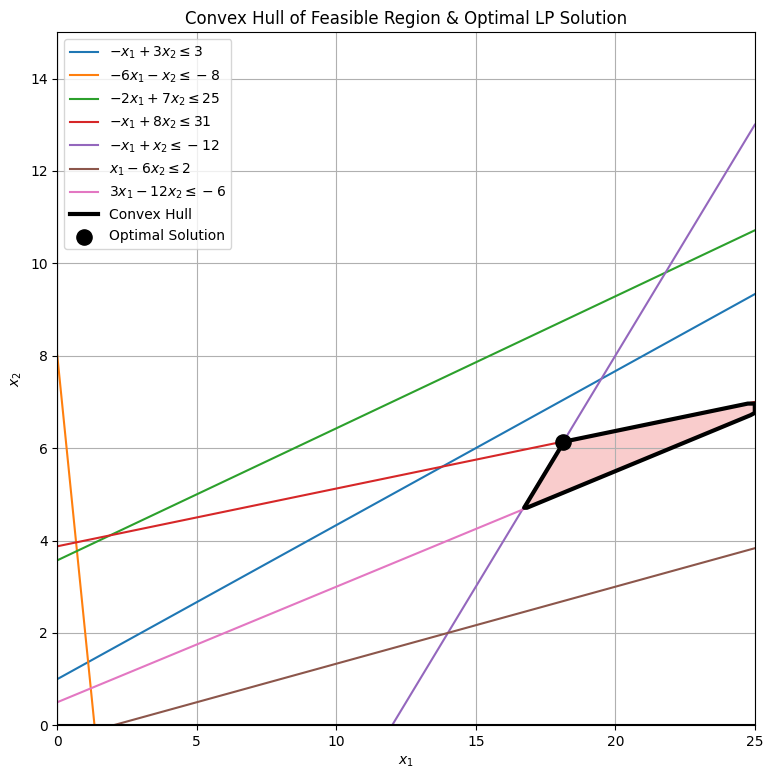

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.spatial import ConvexHull


# -------------------------------
# LINEAR PROGRAMMING PROBLEM
# -------------------------------

# max{-5x1 + 12x2}  <=>  min{5x1 - 12x2}
c = [5, -12]

A = [
    [-1, 3],
    [-6, -1],
    [-2, 7],
    [-1, 8],
    [-1, 1],
    [1, -6],
    [3, -12]
]

b = [3, -8, 25, 31, -12, 2, -6]

# -------------------------------
# INCREMENTAL LINEAR PROGRAMMING
# -------------------------------

def IncrementalLinearProgramming(A, b, c):
    bounds = [(0, None), (0, None)]

    A = np.array(A)
    b = np.array(b)

    # Στο επίπεδο ξεκινάμε με 3 περιορισμούς
    A_curr = A[:3]
    b_curr = b[:3]

    res = linprog(c, A_ub=A_curr, b_ub=b_curr, bounds=bounds)
    if not res.success:
        return None

    # Προσθήκη περιορισμών έναν-έναν
    for i in range(3, len(A)):
        A_curr = A[:i+1]
        b_curr = b[:i+1]

        res = linprog(c, A_ub=A_curr, b_ub=b_curr, bounds=bounds)
        if not res.success:
            return None

    return res


# Επίλυση με αυξητικό αλγόριθμο
res = IncrementalLinearProgramming(A, b, c)

point = res.x

print("Βέλτιστη λύση:", point)
print("Μέγιστη τιμή:", -res.fun)


# -------------------------------
# GRID FOR FEASIBLE REGION
# -------------------------------

x1 = np.linspace(0, 25, 500)
x2 = np.linspace(0, 25, 500)
X1, X2 = np.meshgrid(x1, x2)

constraint1 = X2 <= (3 + X1) / 3
constraint2 = X2 >= 8 - 6*X1
constraint3 = X2 <= (25 + 2*X1) / 7
constraint4 = X2 <= (31 + X1) / 8
constraint5 = X2 <= X1 - 12
constraint6 = X2 >= (X1 - 2) / 6
constraint7 = X2 >= (3*X1 + 6) / 12

feasible = (
    constraint1 &
    constraint2 &
    constraint3 &
    constraint4 &
    constraint5 &
    constraint6 &
    constraint7
)

# -------------------------------
# CONVEX HULL OF FEASIBLE REGION
# -------------------------------

feasible_points = np.column_stack((X1[feasible], X2[feasible]))
hull = ConvexHull(feasible_points)
hull_points = feasible_points[hull.vertices]

# -------------------------------
# PLOTTING
# -------------------------------

plt.figure(figsize=(9, 9))

# Constraints
plt.plot(x1, (3 + x1) / 3, label=r'$-x_1 + 3x_2 \leq 3$')
plt.plot(x1, 8 - 6*x1, label=r'$-6x_1 - x_2 \leq -8$')
plt.plot(x1, (25 + 2*x1) / 7, label=r'$-2x_1 + 7x_2 \leq 25$')
plt.plot(x1, (31 + x1) / 8, label=r'$-x_1 + 8x_2 \leq 31$')
plt.plot(x1, x1 - 12, label=r'$-x_1 + x_2 \leq -12$')
plt.plot(x1, (x1 - 2) / 6, label=r'$x_1 - 6x_2 \leq 2$')
plt.plot(x1, (3*x1 + 6) / 12, label=r'$3x_1 - 12x_2 \leq -6$')

# Feasible region
plt.contourf(X1, X2, feasible, levels=[0.5, 1], colors=['lightcoral'], alpha=0.4)

# Convex hull
plt.plot(
    np.append(hull_points[:, 0], hull_points[0, 0]),
    np.append(hull_points[:, 1], hull_points[0, 1]),
    'k-', linewidth=3, label='Convex Hull'
)

# Optimal point
plt.scatter(point[0], point[1], color='black', s=120, zorder=5, label='Optimal Solution')

# Axes
plt.axhline(0, color='black')
plt.axvline(0, color='black')
plt.xlim(0, 25)
plt.ylim(0, 15)
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.title('Convex Hull of Feasible Region & Optimal LP Solution')
plt.legend()
plt.grid(True)

plt.show()


Delaunay Lifting Algorithm: 0.003515 seconds


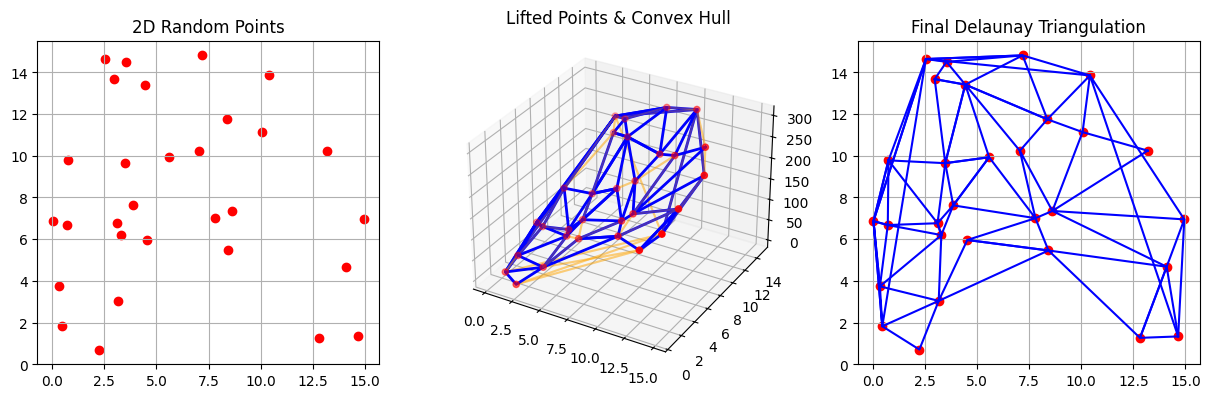

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.spatial import ConvexHull
from mpl_toolkits.mplot3d import Axes3D

# ----------------------------------
# LIFTING FUNCTION
# ----------------------------------

def pointsLifting(points):
    """
    Ανύψωση σημείων (x, y) στην παραβολή z = x^2 + y^2
    """
    lifted = []
    for x, y in points:
        lifted.append([x, y, x**2 + y**2])
    return np.array(lifted)


# ----------------------------------
# DELAUNAY VIA LIFTING
# ----------------------------------

def DelaunayLifting(points):

    # Lifting the points to 3D paraboloid
    liftedPoints = pointsLifting(points)

    # Convex hull in 3D
    hull = ConvexHull(liftedPoints)

    # Keep only lower hull faces
    delaunayFaces = []

    for simplex in hull.simplices:
        v0, v1, v2 = liftedPoints[simplex]

        # Normal vector of the face
        normalVector = np.cross(v1 - v0, v2 - v0)

        # Lower hull => nz < 0
        if normalVector[2] < 0:
            delaunayFaces.append(simplex)

    return np.array(delaunayFaces), liftedPoints, hull


# ----------------------------------
# RANDOM POINTS
# ----------------------------------

np.random.seed(2026)
randomPoints = np.random.uniform(low=0, high=15, size=(30, 2))

# Run algorithm
start = time.perf_counter()
triangles, liftedPoints, hull = DelaunayLifting(randomPoints)
end = time.perf_counter()

print(f"Delaunay Lifting Algorithm: {end - start:.6f} seconds")


# ----------------------------------
# PLOTTING
# ----------------------------------

fig = plt.figure(figsize=(15, 5))

# -------- 2D POINTS --------
ax1 = fig.add_subplot(131)
ax1.scatter(randomPoints[:,0], randomPoints[:,1], color='red')
ax1.set_title("2D Random Points")
ax1.set_aspect('equal')
ax1.grid(True)


# -------- 3D LIFTED POINTS + HULL --------
ax2 = fig.add_subplot(132, projection='3d')
ax2.scatter(
    liftedPoints[:,0],
    liftedPoints[:,1],
    liftedPoints[:,2],
    color='red'
)
ax2.set_title("Lifted Points & Convex Hull")

for simplex in hull.simplices:
    p0, p1, p2 = liftedPoints[simplex]
    normal = np.cross(p1 - p0, p2 - p0)

    xs = liftedPoints[simplex, 0]
    ys = liftedPoints[simplex, 1]
    zs = liftedPoints[simplex, 2]

    xs = np.append(xs, xs[0])
    ys = np.append(ys, ys[0])
    zs = np.append(zs, zs[0])

    if normal[2] < 0:
        ax2.plot(xs, ys, zs, color='blue', linewidth=2)
    else:
        ax2.plot(xs, ys, zs, color='orange', alpha=0.3)


# -------- FINAL DELAUNAY 2D --------
ax3 = fig.add_subplot(133)
ax3.scatter(randomPoints[:,0], randomPoints[:,1], color='red')
ax3.set_title("Final Delaunay Triangulation")
ax3.set_aspect('equal')
ax3.grid(True)

for simplex in triangles:
    pts = randomPoints[simplex]
    pts = np.vstack([pts, pts[0]])
    ax3.plot(pts[:,0], pts[:,1], 'b-')

plt.show()


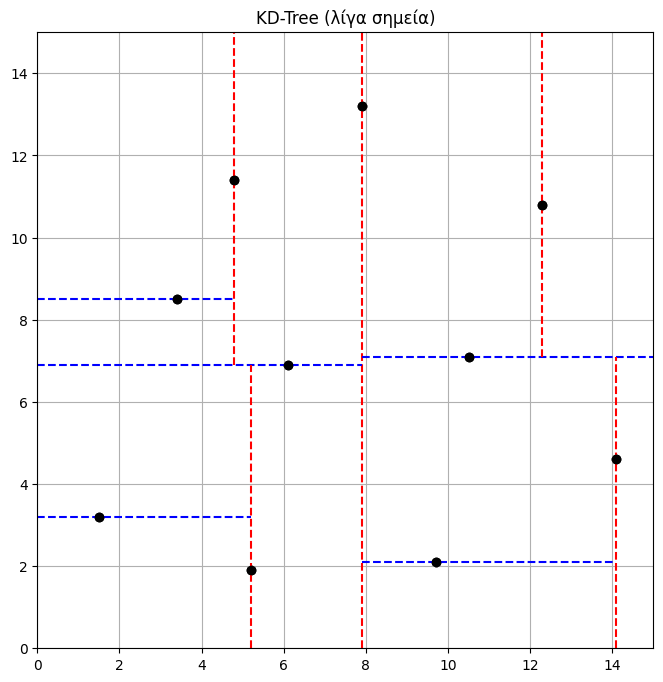

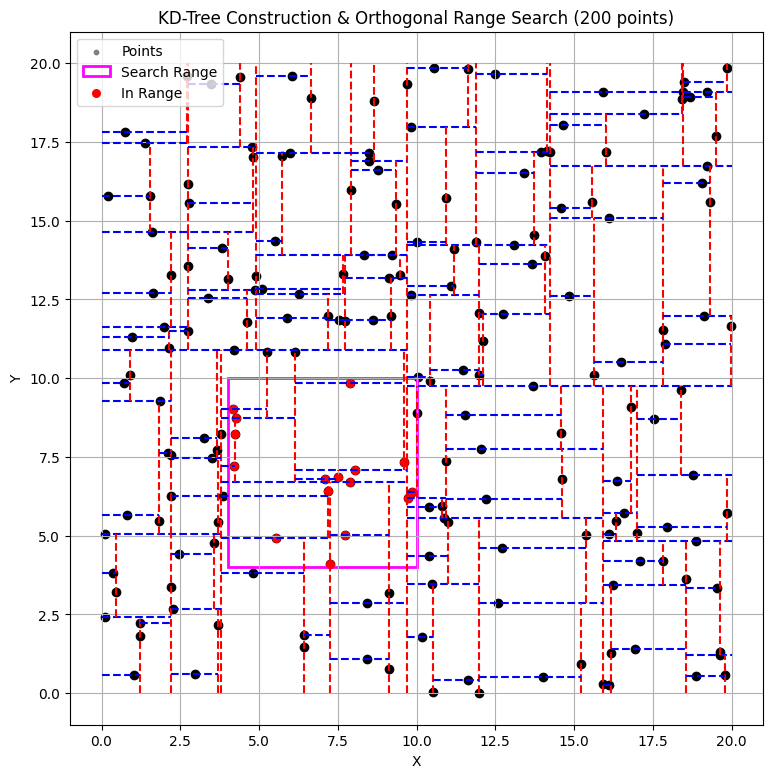

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# ======================================
# KD-TREE NODE
# ======================================

class KDNode:
    def __init__(self, point, axis, left=None, right=None):
        self.point = point
        self.axis = axis
        self.left = left
        self.right = right

# ======================================
# BUILD KD-TREE
# ======================================

def buildKDTree(points, depth=0):
    if len(points) == 0:
        return None

    axis = depth % 2
    points = sorted(points, key=lambda p: p[axis])
    median = len(points) // 2

    return KDNode(
        point=points[median],
        axis=axis,
        left=buildKDTree(points[:median], depth + 1),
        right=buildKDTree(points[median + 1:], depth + 1)
    )

# ======================================
# KD-TREE VISUALIZATION
# ======================================

def plotKDTree(node, bounds):
    if node is None:
        return

    xmin, xmax, ymin, ymax = bounds
    x, y = node.point

    if node.axis == 0:  # vertical split
        plt.plot([x, x], [ymin, ymax], 'r--')
        plotKDTree(node.left, (xmin, x, ymin, ymax))
        plotKDTree(node.right, (x, xmax, ymin, ymax))
    else:               # horizontal split
        plt.plot([xmin, xmax], [y, y], 'b--')
        plotKDTree(node.left, (xmin, xmax, ymin, y))
        plotKDTree(node.right, (xmin, xmax, y, ymax))

    plt.scatter(x, y, color='black')

# ======================================
# ORTHOGONAL RANGE SEARCH
# ======================================

def rangeSearch(node, R, found=None):
    if node is None:
        return []

    if found is None:
        found = []

    (xmin, xmax), (ymin, ymax) = R
    x, y = node.point

    if xmin <= x <= xmax and ymin <= y <= ymax:
        found.append(node.point)

    if node.axis == 0:
        if xmin <= x:
            rangeSearch(node.left, R, found)
        if x <= xmax:
            rangeSearch(node.right, R, found)
    else:
        if ymin <= y:
            rangeSearch(node.left, R, found)
        if y <= ymax:
            rangeSearch(node.right, R, found)

    return found

# ======================================
# INTERMEDIATE PLOT (FEW POINTS)
# ======================================

smallPoints = [
    (1.5, 3.2),
    (4.8, 11.4),
    (6.1, 6.9),
    (9.7, 2.1),
    (12.3, 10.8),
    (14.1, 4.6),
    (3.4, 8.5),
    (7.9, 13.2),
    (10.5, 7.1),
    (5.2, 1.9)
]

treeSmall = buildKDTree(smallPoints)

plt.figure(figsize=(8, 8))
plt.title("KD-Tree (λίγα σημεία)")
plotKDTree(treeSmall, (0, 15, 0, 15))

pts = np.array(smallPoints)
plt.scatter(pts[:,0], pts[:,1], color='black', zorder=5)
plt.xlim(0, 15)
plt.ylim(0, 15)
plt.grid(True)
plt.gca().set_aspect('equal')
plt.show()

# ======================================
# APPLICATION TO 200 POINTS
# ======================================

np.random.seed(100)
points = np.random.uniform(0, 20, (200, 2))
tree = buildKDTree(points.tolist())

R = [(4, 10), (4, 10)]
foundPoints = rangeSearch(tree, R)

# ======================================
# FINAL PLOT WITH RANGE SEARCH
# ======================================

plt.figure(figsize=(9, 9))
plt.scatter(points[:,0], points[:,1], s=10, color='gray', label='Points')
plotKDTree(tree, (0, 20, 0, 20))

xMin, xMax = R[0]
yMin, yMax = R[1]
plt.gca().add_patch(
    plt.Rectangle((xMin, yMin), xMax-xMin, yMax-yMin,
                  fill=False, edgecolor='magenta', linewidth=2,
                  label='Search Range')
)

if len(foundPoints) > 0:
    foundPoints = np.array(foundPoints)
    plt.scatter(foundPoints[:,0], foundPoints[:,1],
                color='red', s=30, label='In Range')

plt.title("KD-Tree Construction & Orthogonal Range Search (200 points)")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid(True)
plt.gca().set_aspect('equal')
plt.show()
